# 08 · Competidores de punta a punta, con la "operación manual"

PSet 4. Compara, con la **misma regla de riesgo y costos** (top 10, pesos 1/vol, sin el 20 % más volátil del mes, tope de portafolio de 1,35 × S&P 500, 15 pb por US$), a todos los competidores en las tres etapas del proyecto:

1. **Validación cruzada** (7 pliegues de 12 meses, 2017-2023, PSet 3).
2. **Hold-out real** (objetivos 2024-01 a 2026-10, una sola vez, PSet 3).
3. **Simulación de producción** (35 lotes con la crisis inducida de 2025-05 a 07, PSet 4, notebook 06).

Competidores: el modelo (LightGBM, v1 @champion), el segundo del PSet 3 (Ridge, v2), B3 (media por acción, la regla manual del PSet 3), B5 (todo el universo por igual), la **operación manual** (`src/operacion_manual.py`: las 10 de mejor Sharpe de 12 meses bajo la volatilidad aprobada) y el efectivo. Las etapas 1 y 2 usan el snapshot del PSet 3 (`obt.parquet`, el de las cifras registradas); la 3, el del PSet 4.

In [1]:
from pathlib import Path
import os, sys, urllib.request
RAIZ = Path.cwd().resolve()
while not (RAIZ / 'monitoreo').exists():
    RAIZ = RAIZ.parent
for p in (RAIZ, RAIZ / 'modelos'):
    sys.path.insert(0, str(p))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, mlflow
from sklearn.base import clone
from src.datos import cargar
from src.pipeline import TARGET, dividir, pliegues, preparar
from src.negocio import REGLA, RiesgoDiario, backtest, portafolio_universo, resumen
from src.modelos.lineas_base import MediaPorAccion
from src.reentrenar import COLUMNAS
from src import operacion_manual as om
from monitoreo.simulacion import simular, etiquetas, LOTES_DERIVA
SEMILLA = 42
DOCS = RAIZ / 'docs'; FIG = DOCS / 'figuras'; SIM = DOCS / 'simulacion'
pd.set_option('display.width', 200)

URI = os.environ.get('MLFLOW_TRACKING_URI', 'http://localhost:5001')
try:
    urllib.request.urlopen(f'{URI}/health', timeout=3)
    mlflow.set_tracking_uri(URI)
    champion = mlflow.sklearn.load_model('models:/portafolio-inversiones-modelo/1')
    ridge = mlflow.sklearn.load_model('models:/portafolio-inversiones-modelo/2')
    origen = f'registro v1 y v2 ({URI})'
except Exception as e:
    champion = mlflow.sklearn.load_model(str(RAIZ / 'tests/fixtures/modelo_champion'))
    ridge = mlflow.sklearn.load_model(str(RAIZ / 'modelos/mlflow/artifacts/2/models/m-7e2b1db0a43a408186b1f4e858ae7f6a/artifacts'))
    origen = f'copias locales (MLflow no disponible: {type(e).__name__})'
dia, _ = cargar(RAIZ / 'modelos/data/obt_dia.parquet', grano='dia')
riesgo = RiesgoDiario(dia)
print('modelos:', origen)

modelos: copias locales (MLflow no disponible: URLError)


## 1 y 2. Validación cruzada y hold-out real (snapshot del PSet 3)

Los modelos se reentrenan en cada pliegue con sus hiperparámetros (`clone`); B3 se ajusta en cada pliegue; la operación manual y B5 no aprenden nada. En el hold-out, los modelos son los registrados.

In [2]:
obt3, meta3 = cargar(RAIZ / 'modelos/data/obt.parquet')
ent, ho = dividir(preparar(obt3))
modelos = {'modelo (LightGBM v1)': champion, 'Ridge (v2)': ridge, 'B3 media por acción': MediaPorAccion()}

def predicciones_cv(m):
    partes = []
    for it, iv in pliegues(ent):
        mm = clone(m).fit(ent[COLUMNAS + ['accion_key']].iloc[it], ent[TARGET].iloc[it])
        v = ent.iloc[iv]
        partes.append(v.assign(pred=mm.predict(v[COLUMNAS + ['accion_key']])))
    return pd.concat(partes, ignore_index=True)

def fila(serie):
    r = resumen(serie)
    return {'sharpe_neto': r['sharpe_neto'], 'retorno_anual_neto': r['retorno_anual_neto'], 'drawdown_max': r['drawdown_max'],
            'turnover_prom': r['turnover_prom'], 'meses': len(serie)}

def efectivo(df):
    t = df.groupby('anio_mes')['rf_mes_siguiente'].first()
    return pd.DataFrame({'bruto': t, 'neto': t, 'rf': t, 'turnover': 0.0})

cv_base = predicciones_cv(MediaPorAccion()).drop(columns='pred')          # mismos meses de validación
etapas = {}
for etapa, base, preds in (('validacion_cruzada', cv_base, {n: predicciones_cv(m) for n, m in modelos.items()}),
                           ('holdout_real', ho, {n: ho.assign(pred=(m.predict(ho[COLUMNAS + ['accion_key']]) if n != 'B3 media por acción'
                                                                   else MediaPorAccion().fit(ent, ent[TARGET]).predict(ho)))
                                                 for n, m in modelos.items()})):
    filas = {n: fila(backtest(p, 'pred', riesgo=riesgo, **REGLA)) for n, p in preds.items()}
    filas['B5 universo igual peso'] = fila(portafolio_universo(base))
    filas[om.NOMBRE] = fila(om.portafolio(base, riesgo=riesgo))
    filas['efectivo'] = fila(efectivo(base)) | {'sharpe_neto': np.nan}
    etapas[etapa] = pd.DataFrame(filas).T
pd.concat(etapas).round(3)

sharpe_neto  retorno_anual_neto  drawdown_max  turnover_prom  meses
validacion_cruzada modelo (LightGBM v1)          0.302               0.060        -0.354          1.888   84.0
                   Ridge (v2)                    0.421               0.074        -0.245          1.804   84.0
                   B3 media por acción           0.585               0.118        -0.263          0.343   84.0
                   B5 universo igual peso        0.544               0.107        -0.293          0.066   84.0
                   operación manual              0.498               0.088        -0.225          1.008   84.0
                   efectivo                        NaN               0.018         0.000          0.000   84.0
holdout_real       modelo (LightGBM v1)          0.869               0.159        -0.115          1.742   34.0
                   Ridge (v2)                   -0.019               0.031        -0.172          1.719   34.0
                   B3 media por acción           0.599               0.134        -0.184          0.342   34.0
                   B5 universo igual peso        0.678               0.126        -0.093          0.086   34.0
                   operación manual              1.201               0.208        -0.069          0.902   34.0
                   efectivo                        NaN               0.043         0.000          0.000   34.0

Control: el Sharpe del modelo en el hold-out debe ser el del PSet 3 (0,87) y el de B5, 0,68.

In [3]:
ho_tabla = etapas['holdout_real']
print(f"modelo {ho_tabla.loc['modelo (LightGBM v1)', 'sharpe_neto']:.2f}; B5 {ho_tabla.loc['B5 universo igual peso', 'sharpe_neto']:.2f}")

modelo 0.87; B5 0.68


## 3. Simulación de producción (snapshot del PSet 4, 35 lotes, crisis inducida)

Se repite la simulación del notebook 06 y se agrega la operación manual sobre los mismos lotes servidos (con la crisis inducida en sus features y en el objetivo). Para la operación manual la crisis cambia `vol_63d` (×2) y el objetivo; su puntaje usa `ret_log_252d`, que el escenario no altera.

In [4]:
obt4, meta4 = cargar(RAIZ / 'modelos/data/obt_p4.parquet')
sim = simular(champion, obt4)
fijo = simular(champion, obt4, aprobar=lambda comp: False)
def etiquetadas(r):
    p = r['predicciones']
    return p[p['ret_pct_mes_siguiente'].notna()]
base4 = etiquetadas(fijo).drop(columns=['pred', 'peso', 'decision', 'modelo_version'])
series = {'sistema (regla del PDF)': backtest(etiquetadas(sim), 'pred', riesgo=riesgo, **REGLA),
          'modelo fijo (v1)': backtest(etiquetadas(fijo), 'pred', riesgo=riesgo, **REGLA),
          'B5 universo igual peso': portafolio_universo(base4),
          om.NOMBRE: om.portafolio(base4, riesgo=riesgo),
          'efectivo': efectivo(base4)}
tab3 = pd.DataFrame({n: fila(s) for n, s in series.items()}).T
tab3.loc['efectivo', 'sharpe_neto'] = np.nan
etapas['simulacion_produccion'] = tab3
comp = pd.concat(etapas)
comp.to_csv(SIM / 'competidores.csv')
lotes = pd.DataFrame({n: s['neto'] for n, s in series.items()})
lotes.to_csv(SIM / 'competidores_por_lote.csv')
tab3.round(3)

,sharpe_neto,retorno_anual_neto,drawdown_max,turnover_prom,meses
sistema (regla del PDF),-0.229,-0.019,-0.369,1.770,34.0
modelo fijo (v1),0.051,0.037,-0.335,1.760,34.0
B5 universo igual peso,-0.131,0.012,-0.266,0.086,34.0
operación manual,0.346,0.091,-0.305,0.895,34.0
efectivo,NaN,0.043,0.000,0.000,34.0


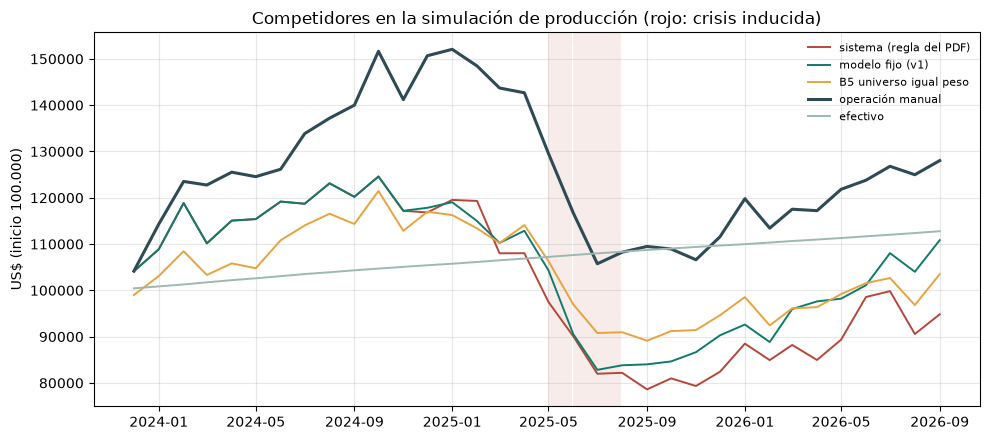

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colores = {'sistema (regla del PDF)': '#B5473A', 'modelo fijo (v1)': '#0F7B6C', 'B5 universo igual peso': '#E8A33D',
           om.NOMBRE: '#2E4A55', 'efectivo': '#9DB8B3'}
fechas = pd.PeriodIndex(lotes.index.astype(str), freq='M').to_timestamp()
for c in lotes:
    ax.plot(fechas, 100_000 * (1 + lotes[c]).cumprod(), label=c, color=colores[c], lw=2.2 if c == om.NOMBRE else 1.4)
for m in LOTES_DERIVA:
    t = pd.Period(str(m), freq='M').to_timestamp(); ax.axvspan(t, t + pd.offsets.MonthEnd(1), color='#B5473A', alpha=0.1, lw=0)
ax.set_ylabel('US$ (inicio 100.000)'); ax.grid(alpha=.3); ax.legend(frameon=False, fontsize=8)
ax.set_title('Competidores en la simulación de producción (rojo: crisis inducida)')
fig.tight_layout(); fig.savefig(FIG / 'competidores_por_lote.png', dpi=150)

## 4. Lectura

La tabla `docs/simulacion/competidores.csv` resume las tres etapas. La conclusión (si la operación manual le gana al modelo, en qué etapa y por qué) se escribe en el documento técnico, sección 9, y en la presentación, con estas cifras.

In [6]:
res = comp['sharpe_neto'].unstack(0)[['validacion_cruzada', 'holdout_real', 'simulacion_produccion']]
res.round(2)

,validacion_cruzada,holdout_real,simulacion_produccion
B3 media por acción,0.58,0.60,NaN
B5 universo igual peso,0.54,0.68,-0.13
Ridge (v2),0.42,-0.02,NaN
efectivo,NaN,NaN,NaN
modelo (LightGBM v1),0.30,0.87,NaN
modelo fijo (v1),NaN,NaN,0.05
operación manual,0.50,1.20,0.35
sistema (regla del PDF),NaN,NaN,-0.23
